# Mission d'Analyse : Département Business Intelligence Walmart

### L'objectif étant d'analyser les données afin d’aider le comité de direction à identifier des perspectives de croissance ou d’optimisation

### Tout d'abord, nous allons importer les données en utilisant la bibliotheque pandas de python

In [4]:
import pandas as pd
df = pd.read_csv("Walmart.csv")
print(df.head())

print(df.info())


   transaction_id  customer_id  product_id product_name     category  \
0               1         2824         843       Fridge  Electronics   
1               2         1409         135           TV  Electronics   
2               3         5506         391       Fridge  Electronics   
3               4         5012         710   Smartphone  Electronics   
4               5         4657         116       Laptop  Electronics   

   quantity_sold  unit_price transaction_date  store_id   store_location  ...  \
0              3      188.46  3/31/2024 21:46         3        Miami, FL  ...   
1              4     1912.04  7/28/2024 12:45         5       Dallas, TX  ...   
2              4     1377.75   6/10/2024 4:55         1  Los Angeles, CA  ...   
3              5      182.31   8/15/2024 1:03         5        Miami, FL  ...   
4              3      499.28   9/13/2024 0:45         6      Chicago, IL  ...   

   customer_loyalty_level  payment_method  promotion_applied  \
0               

### Par la suite nous Identifions les valeurs manquantes ou incohérentes

In [35]:
print(df.isnull().sum())


transaction_id               0
customer_id                  0
product_id                   0
product_name                 0
category                     0
quantity_sold                0
unit_price                   0
transaction_date             0
store_id                     0
store_location               0
inventory_level              0
reorder_point                0
reorder_quantity             0
supplier_id                  0
supplier_lead_time           0
customer_age                 0
customer_gender              0
customer_income              0
customer_loyalty_level       0
payment_method               0
promotion_applied            0
promotion_type            3407
weather_conditions           0
holiday_indicator            0
weekday                      0
stockout_indicator           0
forecasted_demand            0
actual_demand                0
montant                      0
dtype: int64


### Nous constatons qu'il y'a 3407 valeurs manquantes sur la colonne "promotion_type", voila pourquoi je ne vais pas inclure la promotion dans mon analyse

### Puis je supprime les doublons pour évider les erreurs d'analyse

In [41]:
# Supprimer les lignes en double
df = df.drop_duplicates()


### Avec la quantité et le prix unitaire de chaque produit nous pouvons déterminer le montant généré par chaque produit

In [42]:
df["montant"] = (df["quantity_sold"] * df["unit_price"])

print(df)

      transaction_id  customer_id  product_id     product_name     category  \
0                  1         2824         843           Fridge  Electronics   
1                  2         1409         135               TV  Electronics   
2                  3         5506         391           Fridge  Electronics   
3                  4         5012         710       Smartphone  Electronics   
4                  5         4657         116           Laptop  Electronics   
...              ...          ...         ...              ...          ...   
4995            4996         6898         852       Headphones   Appliances   
4996            4997         8412         886           Laptop   Appliances   
4997            4998         8331         934           Fridge  Electronics   
4998            4999         7505         439           Laptop   Appliances   
4999            5000         1003         926  Washing Machine   Appliances   

      quantity_sold  unit_price transaction_date  s

### Pour une meilleure analyse nous mettons en evidence la quantité totale vendue par produit et par catégorie 

In [43]:
ventes_par_categorie = df.groupby("category")["montant"].sum()
print(ventes_par_categorie)


category
Appliances     7321969.65
Electronics    7941631.80
Name: montant, dtype: float64


### Nous pouvons voir ces résultats plus clairement à travers le graphe suivant

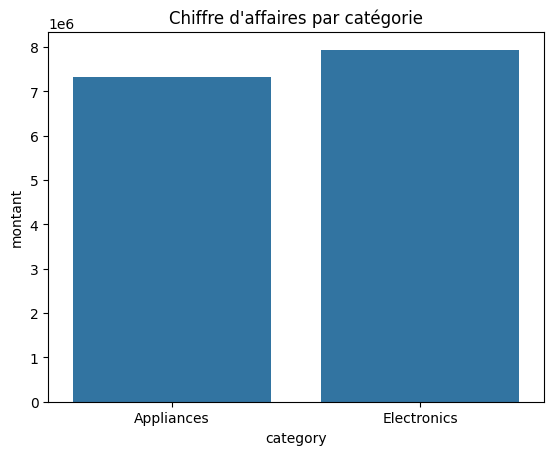

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# Chiffre d'affaires par catégorie
sns.barplot(x=ventes_par_categorie.index, y=ventes_par_categorie.values)
plt.title("Chiffre d'affaires par catégorie")
plt.xlabel("category")
plt.ylabel("montant")
plt.show()


### Nous remarquons aue la catégorie "Electronics" génère le plus de revenu

### Nous déterminons maintenant le chiffre d'affaire par localisation de magasin

In [17]:
CA_magasin = df.groupby("store_location")["montant"].sum()
print(CA_magasin)

store_location
Chicago, IL        3156726.82
Dallas, TX         2903930.74
Los Angeles, CA    3276299.63
Miami, FL          2962567.02
New York, NY       2964077.24
Name: montant, dtype: float64


### Pour une meilleure visibilité nous pouvons le ranger par ordre décroissant

In [20]:
CA_magasin = CA_magasin.sort_values(ascending=False)

print(CA_magasin)


store_location
Los Angeles, CA    3276299.63
Chicago, IL        3156726.82
New York, NY       2964077.24
Miami, FL          2962567.02
Dallas, TX         2903930.74
Name: montant, dtype: float64


### Nous pouvons également mettre cela en évidence via un graphe et montrer ainsi que "Los Angeles génère" le plus de revenu

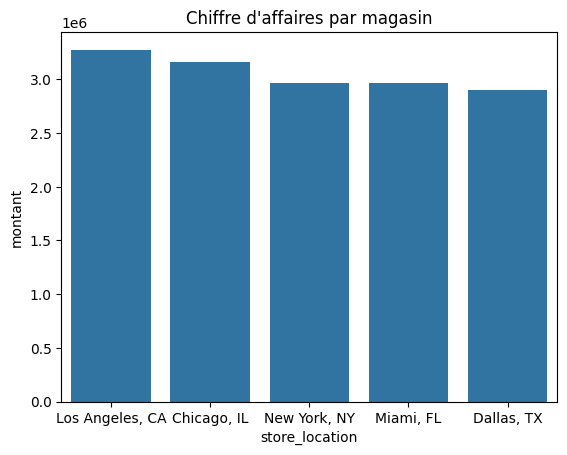

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

# Chiffre d'affaires par magasin
sns.barplot(x=CA_magasin.index, y=CA_magasin.values)
plt.title("Chiffre d'affaires par magasin")
plt.xlabel("store_location")
plt.ylabel("montant")
plt.show()


### Nous allons voir l'impact de la météo sur les ventes

In [31]:
meteo = df.groupby("weather_conditions")["montant"].sum()
meteo = meteo.sort_values(ascending=False)

print(meteo)

weather_conditions
Sunny     3979603.69
Cloudy    3878416.82
Stormy    3843358.52
Rainy     3562222.42
Name: montant, dtype: float64


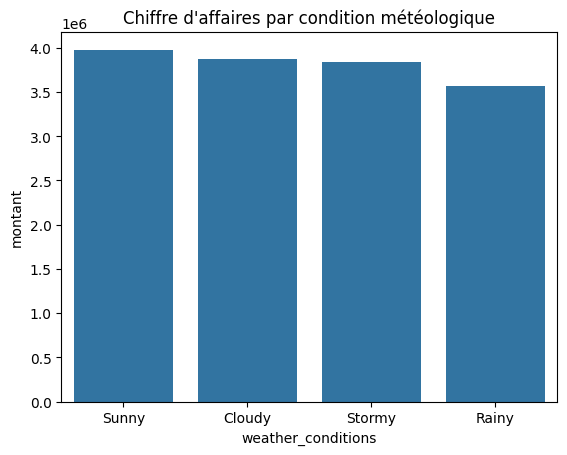

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

# Chiffre d'affaires par condition météologique
sns.barplot(x=meteo.index, y=meteo.values)
plt.title("Chiffre d'affaires par condition météologique")
plt.xlabel("weather_conditions")
plt.ylabel("montant")
plt.show()


### Nous constatons que le magasin fait beaucoup  de ventes lorsqu'il y a du soleil et beaucoup moin lorsqu'il pleut

### Maintenant nous allons exprimer les ventes en fonction du genre

In [36]:
genre = df.groupby("customer_gender")["montant"].sum()
genre= genre.sort_values(ascending=False)

print(genre)

customer_gender
Female    5193570.83
Other     5191936.83
Male      4878093.79
Name: montant, dtype: float64


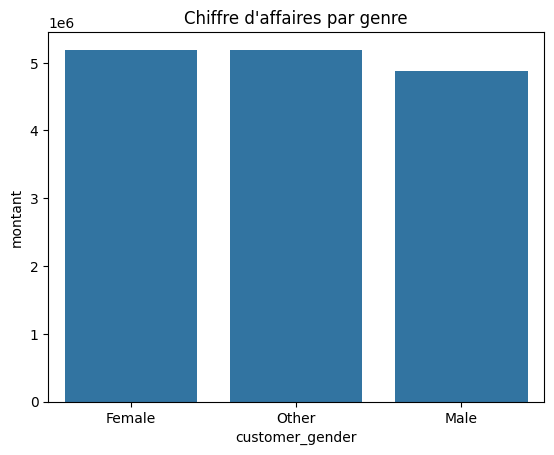

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

# Chiffre d'affaires par genre
sns.barplot(x=genre.index, y=genre.values)
plt.title("Chiffre d'affaires par genre")
plt.xlabel("customer_gender")
plt.ylabel("montant")
plt.show()


### Nous constatons que les femmes font beaucoup plus de vente que les hommes et les autres

### Par la suite nous pouvons aussi voir les jours de la semaine ou les clients achètent le plus

In [38]:
jour = df.groupby("weekday")["montant"].sum()
jour = jour.sort_values(ascending=False)

print(jour)

weekday
Thursday     2436640.72
Monday       2433795.67
Saturday     2222858.28
Tuesday      2126494.17
Wednesday    2095912.06
Friday       2009799.42
Sunday       1938101.13
Name: montant, dtype: float64


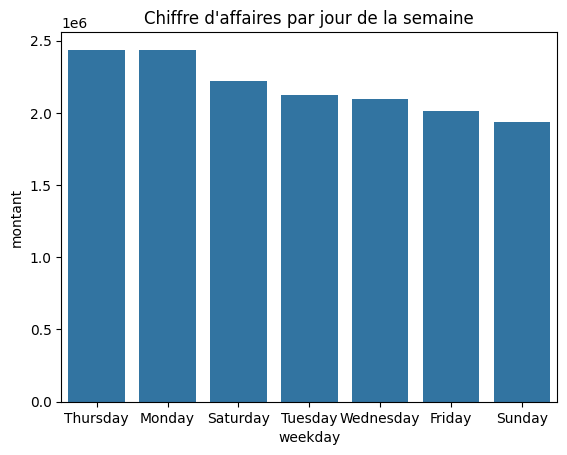

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

# Chiffre d'affaires par jour de la semaine
sns.barplot(x=jour.index, y=jour.values)
plt.title("Chiffre d'affaires par jour de la semaine")
plt.xlabel("weekday")
plt.ylabel("montant")
plt.show()


## Conclusion

### En conclusion, il apparait  clairement selon les analyses que:
* Le jeudi est le jour ou il ya le plus de vente
* Les femmes achètent beaucoup plus les produits
* Pendant la saison sèche il ya une augmentation considérable du chiffre d'affaire
* Le magasin situé à Los angeles fait le plus de C.A

### Pour finir j'exporte mon jeu de données pour générer des graphes sur power bi

In [44]:
# Sauvegarder les données nettoyées dans un nouveau fichier
df.to_csv("Walmart_cleaned.csv", index=False)
